# 02 · Baseline: the deployed MLP under domain shift

The game ships `mnist_tfjs_model/`, converted from `mlp_training/saved_model/`
(Dense 512 ReLU → Dropout 0.2 → Dense 64 ReLU → Dense 10 softmax, ~435k parameters,
98.28% on the MNIST test set). Here we load that exact SavedModel and evaluate it on the
test sets from notebook 01.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

import evaluate as ev

plt.rcParams['figure.dpi'] = 80
sets = ev.load_test_sets()
print({k: v[0].shape for k, v in sets.items()})

{'mnist': (10000, 28, 28), 'mnist_pipe': (10000, 28, 28), 'pad_skel': (10000, 28, 28), 'pad_tmpl': (10000, 28, 28)}


In [2]:
loaded = tf.saved_model.load('../saved_model')
infer = loaded.signatures['serving_default']
in_name = list(infer.structured_input_signature[1].keys())[0]
out_name = list(infer.structured_outputs.keys())[0]
print('input', in_name, infer.structured_input_signature[1][in_name], '| output', out_name)

def mlp_predict(x, batch=2048):
    x = x.reshape(len(x), 784).astype(np.float32)
    return np.concatenate([infer(**{in_name: tf.constant(x[i:i + batch])})[out_name].numpy()
                           for i in range(0, len(x), batch)])

n_params = sum(int(np.prod(v.shape)) for v in loaded.variables)
print(f'parameters: {n_params:,}')

input keras_tensor TensorSpec(shape=(None, 784), dtype=tf.float32, name='keras_tensor') | output output_0
parameters: 435,404


## Accuracy per test set

mnist        98.28%
mnist_pipe   97.97%
pad_skel     93.90%
pad_tmpl     92.88%


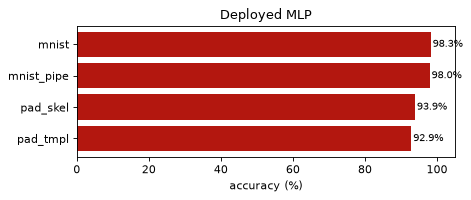

In [3]:
acc = ev.accuracy_table(mlp_predict, sets)
for k, v in acc.items():
    print(f'{k:11s} {v:7.2%}')
plt.figure(figsize=(6, 2.6))
plt.barh(list(acc)[::-1], [v * 100 for v in acc.values()][::-1], color='#b3170f')
for i, v in enumerate(list(acc.values())[::-1]):
    plt.text(v * 100 + 0.5, i, f'{v:.1%}', va='center', fontsize=9)
plt.xlim(0, 105); plt.xlabel('accuracy (%)'); plt.title('Deployed MLP'); plt.tight_layout(); plt.show()

## Where it fails

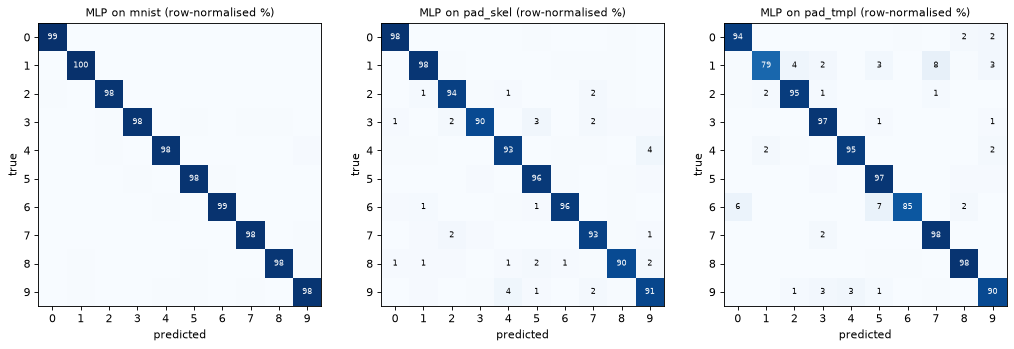

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, name in zip(ax, ['mnist', 'pad_skel', 'pad_tmpl']):
    x, y = sets[name]
    ev.plot_confusion(y, mlp_predict(x).argmax(1), f'MLP on {name} (row-normalised %)', a)
plt.tight_layout(); plt.show()

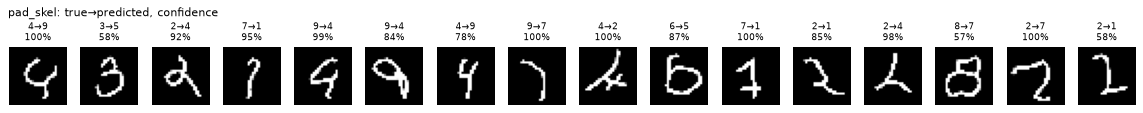

pad_skel per-digit accuracy: 0:98% 1:98% 2:94% 3:90% 4:93% 5:96% 6:96% 7:93% 8:90% 9:91%


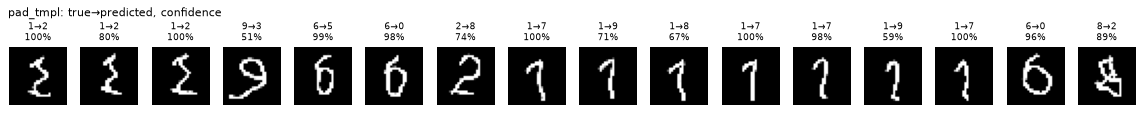

pad_tmpl per-digit accuracy: 0:94% 1:79% 2:95% 3:97% 4:95% 5:97% 6:85% 7:98% 8:98% 9:90%


In [5]:
for name in ['pad_skel', 'pad_tmpl']:
    x, y = sets[name]
    p = mlp_predict(x)
    ev.show_errors(x, y, p.argmax(1), p, title=f'{name}: true→predicted, confidence')
    per_class = [(p.argmax(1)[y == d] == d).mean() for d in range(10)]
    print(name, 'per-digit accuracy:', ' '.join(f'{d}:{a:.0%}' for d, a in enumerate(per_class)))

## Confidence: are the mistakes at least uncertain?

The game only acts on a reading when it is confident enough (see `decide()`), so a model
that is wrong *and* confident is worse than one that is wrong and unsure.

In [6]:
for name in ['mnist', 'pad_skel', 'pad_tmpl']:
    x, y = sets[name]
    p = mlp_predict(x)
    conf, ok = p.max(1), p.argmax(1) == y
    print(f'{name:9s} mean confidence when right {conf[ok].mean():.2f}, when wrong {conf[~ok].mean():.2f}; '
          f'wrong with >90% confidence: {(~ok & (conf > 0.9)).mean():.1%} of all samples')

mnist     mean confidence when right 1.00, when wrong 0.84; wrong with >90% confidence: 0.9% of all samples
pad_skel  mean confidence when right 0.99, when wrong 0.89; wrong with >90% confidence: 3.9% of all samples
pad_tmpl  mean confidence when right 0.99, when wrong 0.87; wrong with >90% confidence: 4.3% of all samples


## What the player experiences

`decide()` in `js/game/handwriting.js` combines the probabilities with the answers on screen:
if the top digit is not an answer but a runner-up is (≥ 20% and ≥ 35% of the top), the
runner-up wins. With 1–3 enemies on screen this hides many recognition errors. We simulate
the true answer plus 0–2 random other answers.

In [7]:
for name in ['pad_skel', 'pad_tmpl']:
    x, y = sets[name]
    p = mlp_predict(x)
    for k in [1, 2, 3]:
        hit, wrong, other = ev.game_hit_rate(p, y, k)
        print(f'{name:9s} {k} answer(s) on screen: accepted {hit:6.1%}  wrong enemy {wrong:5.1%}  '
              f'miss/unclear {other:5.1%}   (raw accuracy {(p.argmax(1) == y).mean():.1%})')

pad_skel  1 answer(s) on screen: accepted  94.8%  wrong enemy  0.0%  miss/unclear  5.2%   (raw accuracy 93.9%)


pad_skel  2 answer(s) on screen: accepted  94.7%  wrong enemy  0.8%  miss/unclear  4.6%   (raw accuracy 93.9%)


pad_skel  3 answer(s) on screen: accepted  94.5%  wrong enemy  1.6%  miss/unclear  3.9%   (raw accuracy 93.9%)


pad_tmpl  1 answer(s) on screen: accepted  94.0%  wrong enemy  0.0%  miss/unclear  6.0%   (raw accuracy 92.9%)


pad_tmpl  2 answer(s) on screen: accepted  93.9%  wrong enemy  0.9%  miss/unclear  5.2%   (raw accuracy 92.9%)


pad_tmpl  3 answer(s) on screen: accepted  93.8%  wrong enemy  1.7%  miss/unclear  4.6%   (raw accuracy 92.9%)


## 小结

| 测试集 | MLP 准确率 |
|---|---|
| MNIST test | 98.28% |
| MNIST 走浏览器预处理 | 97.97% |
| pad_skel（MNIST 字形 + 游戏笔画渲染） | 93.90% |
| pad_tmpl（新字形 + 200 个模拟书写者） | 92.88% |

- 仅浏览器预处理本身几乎不掉点（-0.3%）；真正的问题是**笔画渲染和字形的域偏移**：错误率从 1.7% 涨到 6–7%（约 4 倍）。
- 错误集中在少数类：`pad_tmpl` 上 1 只有 79%（最常见 1→7、1→2）、6 只有 85%（6→5、6→0）；
  `pad_skel` 上最常见的是 9↔4、3→5、7↔2。
- 错误往往是**高置信度**的：有约 4% 的样本"错且置信度 > 90%"（MNIST 上只有 0.9%），这类错误 `decide()` 也救不回来。
- `decide()` 结合屏幕上的候选答案只把"玩家感受到的成功率"提高约 1 个百分点，同时屏幕上答案越多，打错敌人的比例越高（~1.7%）。
  所以提升模型本身是有意义的。